## 0. Environment Setup

This notebook is designed to run in Google Colab.

The project files are downloaded from GitHub, and the required Python libraries are installed before running the experiments.

The CatFLW dataset is downloaded separately in Section 1 and is not included in the GitHub repository.

For model training, a GPU runtime is recommended (Runtime → Change runtime type → GPU).

In [ ]:
from pathlib import Path
import os

# Replace these with your GitHub username and repository name
GITHUB_USERNAME = "YOUR_USERNAME"
REPO_NAME = "catflw-landmark-detection"

REPO_URL = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
PROJECT_DIR = Path("/content") / REPO_NAME

# Download project files
if not PROJECT_DIR.exists():
    !git clone "{REPO_URL}" "{PROJECT_DIR}"

# Set the working directory
os.chdir(PROJECT_DIR)

# Install project dependencies
%pip install -q -r requirements.txt
%pip install -q scipy

# Verify that essential files are present
required_files = [
    "train.py",
    "models.py",
    "catflw_dataset.py",
    "eval_utils.py",
]

for filename in required_files:
    assert Path(filename).exists(), f"Missing project file: {filename}"

print(f"Project ready: {Path.cwd()}")

1. Dataset Setup

This project uses the CatFLW dataset, containing cat facial images annotated with 48 landmarks.
The dataset is downloaded from Kaggle and stored temporarily in the Google Colab environment. This avoids requiring access to a personal Google Drive or including the dataset in the repository.

In [ ]:
from pathlib import Path

# Directory for the CatFLW dataset
DATA_DIR = Path("/content/catflw_data")

# Install Kaggle and download the dataset
%pip install -q kaggle
!kaggle datasets download -d georgemartvel/catflw -p "{DATA_DIR}" --unzip

In [ ]:
# Check that the dataset contains images and annotations
image_files = list(DATA_DIR.rglob("*.png"))
label_files = list(DATA_DIR.rglob("*.json"))

print(f"Images: {len(image_files)}")
print(f"Annotations: {len(label_files)}")

## 2. Dataset Inspection

Before training, the dataset is checked to ensure that the images and their corresponding landmark annotations can be loaded correctly.

Each image contains 48 annotated facial landmarks, represented by their (x, y) coordinates.

In [ ]:
from catflw_dataset import load_annotations

# Load images and their corresponding landmark annotations
records, image_dir = load_annotations(DATA_DIR)

print(f"Valid images: {len(records)}")
print(f"Image directory: {image_dir}")
print(f"Landmarks per image: {len(records[0]['landmarks'])}")

## 3. Model Architecture Inspection

Three CNN architectures are evaluated: ShuffleNetV2, EfficientNetB0, and MobileNetV3.

Before training, the total number of parameters and trainable parameters are calculated for each architecture. This provides an overview of model complexity and allows the architectures to be compared in terms of their size.

Pretrained weights are disabled for this inspection because only the model architecture and parameter counts are required.

In [ ]:
from models import build_model, AVAILABLE_BACKBONES

# Compare the number of parameters in each CNN model
for backbone in AVAILABLE_BACKBONES:
    model = build_model("coord", backbone, pretrained=False)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    print(f"{backbone}")
    print(f"  Total parameters:     {total_params:,}")
    print(f"  Trainable parameters: {trainable_params:,}\n")

shufflenet_v2_x1_0: 1,540,676 total | 1,540,676 trainable
efficientnet_b0: 4,360,156 total | 4,360,156 trainable
mobilenetv3_small_100: 1,804,928 total | 1,804,928 trainable


4. Model Comparison Experiments

This section compares three CNN architectures—ShuffleNetV2, EfficientNetB0, and MobileNetV3—using two facial landmark prediction approaches:

Coordinate regression: Predicts the (x, y) coordinates of all 48 landmarks directly.

Heatmap regression: Predicts a spatial heatmap for each landmark, from which coordinates are extracted.

Each model is trained for 30 epochs using a learning rate of 0.0001. Performance is evaluated using Normalized Root Mean Squared Error (NRMSE), where lower values indicate more accurate landmark predictions.

4.1 ShuffleNetV2 — Coordinate Regression

The first experiment trains ShuffleNetV2 to predict the 48 facial landmark coordinates directly using Wing loss.

In [ ]:
# ShuffleNetV2: coordinate regression
!python train.py \
    --approach coord \
    --backbone shufflenet_v2_x1_0 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/coord_shufflenet" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/shufflenet_v2_x1_0] epoch 1/30 train_loss=112.2730 val_nrmse=48.87%
[coord/shufflenet_v2_x1_0] epoch 2/30 train_loss=110.0045 val_nrmse=46.83%
[coord/shufflenet_v2_x1_0] epoch 3/30 train_loss=100.3583 val_nrmse=40.74%
[coord/shufflenet_v2_x1_0] epoch 4/30 train_loss=81.7863 val_nrmse=32.88%
[coord/shufflenet_v2_x1_0] epoch 5/30 train_loss=54.2017 val_nrmse=20.52%
[coord/shufflenet_v2_x1_0] epoch 6/30 train_loss=33.8572 val_nrmse=14.32%
[coord/shufflenet_v2_x1_0] epoch 7/30 train_loss=29.6433 val_nrmse=13.28%
[coord/shufflenet_v2_x1_0] epoch 8/30 train_loss=28.5107 val_nrmse=12.94%
[coord/shufflenet_v2_x1_0] epoch 9/30 train_loss=28.3191 val_nrmse=12.84%
[coord/shufflenet_v2_x1_0] epoch 10/30 train_loss=28.3248 val_nrmse=12.58%
[coord/shufflenet_v2_x1_0] epoch 11/30 train_lo

### 4.2 ShuffleNetV2 — Heatmap Regression

This experiment evaluates ShuffleNetV2 using heatmap regression.

Instead of directly predicting landmark coordinates, the model generates a heatmap for each of the 48 facial landmarks. The predicted landmark positions are then extracted from these heatmaps.

The results are compared with the coordinate-regression approach to investigate how the prediction method affects landmark localization accuracy.

In [ ]:
# ShuffleNetV2: heatmap regression
!python train.py \
    --approach heatmap \
    --backbone shufflenet_v2_x1_0 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/heatmap_shufflenet" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[heatmap/shufflenet_v2_x1_0] epoch 1/30 train_loss=0.0154 val_nrmse=15.98%
[heatmap/shufflenet_v2_x1_0] epoch 2/30 train_loss=0.0037 val_nrmse=15.98%
[heatmap/shufflenet_v2_x1_0] epoch 3/30 train_loss=0.0034 val_nrmse=15.97%
[heatmap/shufflenet_v2_x1_0] epoch 4/30 train_loss=0.0032 val_nrmse=15.97%
[heatmap/shufflenet_v2_x1_0] epoch 5/30 train_loss=0.0030 val_nrmse=15.98%
[heatmap/shufflenet_v2_x1_0] epoch 6/30 train_loss=0.0029 val_nrmse=15.97%
[heatmap/shufflenet_v2_x1_0] epoch 7/30 train_loss=0.0028 val_nrmse=15.97%
[heatmap/shufflenet_v2_x1_0] epoch 8/30 train_loss=0.0026 val_nrmse=15.97%
[heatmap/shufflenet_v2_x1_0] epoch 9/30 train_loss=0.0025 val_nrmse=15.95%
[heatmap/shufflenet_v2_x1_0] epoch 10/30 train_loss=0.0023 val_nrmse=15.96%
[heatmap/shufflenet_v2_x1_0] epoch 11/30

### 4.3 EfficientNetB0 — Coordinate Regression

This experiment evaluates EfficientNetB0 using direct coordinate regression.

The model predicts the (x, y) coordinates of all 48 facial landmarks using a pretrained EfficientNetB0 backbone and a regression head.

Wing loss is used during training, and the resulting NRMSE is compared with ShuffleNetV2 to investigate how the choice of CNN architecture affects landmark localization accuracy.

In [ ]:
# EfficientNetB0: coordinate regression
!python train.py \
    --approach coord \
    --backbone efficientnet_b0 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/coord_efficientnet" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records

model.safetensors: downloading bytes:  32% 6.85M/21.4M [00:00<00:01, 8.93MB/s,  254kB/s  ]
model.safetensors: reconstructing file:  26% 5.55M/21.4M [00:01<00:02, 5.39MB/s]
model.safetensors: downloading bytes:  59% 12.5M/21.4M [00:01<00:00, 14.7MB/s,  849kB/s  ]
model.safetensors: downloading bytes:  86% 18.4M/21.4M [00:01<00:00, 19.0MB/s, 1.46MB/s  ]
model.safetensors: downloading bytes: 100% 20.2M/20.2M [00:01<00:00, 14.6MB/s, 1.93MB/s  ]
model.safetensors: reconstructing file: 100% 21.4M/21.4M [00:01<00:00, 15.5MB/s, 2.05MB/s  ]
[coord/efficientnet_b0] epoch 1/30 train_loss=109.2617 val_nrmse=39.14%
[coord/efficientnet_b0] epoch 2/30 train_loss=72.9786 val_nrmse=26.25%
[coord/efficientnet_b0] epoch 3/30 train_loss=35.6564 val_nrmse=13.83%
[coord/efficientnet_b0] epoch 4/30 tra

### 4.4 MobileNetV3 — Coordinate Regression

This experiment evaluates MobileNetV3 using direct coordinate regression.

The model predicts the (x, y) coordinates of all 48 facial landmarks using a pretrained MobileNetV3 backbone and a regression head.

Wing loss is used during training, and the resulting NRMSE is compared with ShuffleNetV2 and EfficientNetB0 to investigate how the choice of CNN architecture affects landmark localization accuracy.

In [ ]:
# MobileNetV3: coordinate regression
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/coord_mobilenet" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records

model.safetensors: downloading bytes:  81% 8.28M/10.2M [00:01<00:00, 15.1MB/s,  269kB/s  ]
model.safetensors: downloading bytes: 100% 9.76M/9.76M [00:01<00:00, 7.15MB/s,  943kB/s  ]
model.safetensors: reconstructing file: 100% 10.2M/10.2M [00:01<00:00, 7.50MB/s,  993kB/s  ]
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=88.1680 val_nrmse=15.09%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=31.9389 val_nrmse=12.88%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=30.9509 val_nrmse=12.44%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.5700 val_nrmse=12.80%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.1213 val_nrmse=12.39%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.9755 val_nrmse=12.13%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=2

### 4.5 ShuffleNetV2 — Heatmap Regression (Batch Size 8)

This experiment repeats ShuffleNetV2 heatmap regression using a smaller batch size of 8 instead of 16.

All other training settings remain unchanged. This run allows the heatmap approach to be evaluated with a reduced batch size while preserving the earlier experiment for comparison.

In [ ]:
# ShuffleNetV2: heatmap regression with batch size 8
!python train.py \
    --approach heatmap \
    --backbone shufflenet_v2_x1_0 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/heatmap_shufflenet_v2" \
    --epochs 30 \
    --batch_size 8 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[heatmap/shufflenet_v2_x1_0] epoch 1/30 train_loss=0.0062 val_nrmse=15.82%
[heatmap/shufflenet_v2_x1_0] epoch 2/30 train_loss=0.0010 val_nrmse=15.85%
[heatmap/shufflenet_v2_x1_0] epoch 3/30 train_loss=0.0010 val_nrmse=15.86%
[heatmap/shufflenet_v2_x1_0] epoch 4/30 train_loss=0.0010 val_nrmse=15.87%
[heatmap/shufflenet_v2_x1_0] epoch 5/30 train_loss=0.0010 val_nrmse=15.89%
[heatmap/shufflenet_v2_x1_0] epoch 6/30 train_loss=0.0009 val_nrmse=15.88%
[heatmap/shufflenet_v2_x1_0] epoch 7/30 train_loss=0.0009 val_nrmse=15.86%
[heatmap/shufflenet_v2_x1_0] epoch 8/30 train_loss=0.0009 val_nrmse=15.84%
[heatmap/shufflenet_v2_x1_0] epoch 9/30 train_loss=0.0009 val_nrmse=15.83%
[heatmap/shufflenet_v2_x1_0] epoch 10/30 train_loss=0.0009 val_nrmse=15.81%
[heatmap/shufflenet_v2_x1_0] epoch 11/30

### 4.6 EfficientNetB0 — Heatmap Regression

This experiment evaluates EfficientNetB0 using heatmap regression.

The model predicts a separate heatmap for each of the 48 facial landmarks. The predicted landmark coordinates are then extracted from these heatmaps using soft-argmax.

The results are compared with EfficientNetB0 coordinate regression to investigate how the prediction approach affects landmark localization accuracy.

A batch size of 8 is used for this experiment.

In [ ]:
# EfficientNetB0: heatmap regression
!python train.py \
    --approach heatmap \
    --backbone efficientnet_b0 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/heatmap_efficientnet" \
    --epochs 30 \
    --batch_size 8 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
[heatmap/efficientnet_b0] epoch 1/30 train_loss=0.0178 val_nrmse=16.04%
[heatmap/efficientnet_b0] epoch 2/30 train_loss=0.0038 val_nrmse=16.10%
[heatmap/efficientnet_b0] epoch 3/30 train_loss=0.0021 val_nrmse=16.10%
[heatmap/efficientnet_b0] epoch 4/30 train_loss=0.0014 val_nrmse=16.10%
[heatmap/efficientnet_b0] epoch 5/30 train_loss=0.0012 val_nrmse=16.11%
[heatmap/efficientnet_b0] epoch 6/30 train_loss=0.0011 val_nrmse=16.09%
[heatmap/efficientnet_b0] epoch 7/30 train_loss=0.0011 val_nrmse=16.11%
[heatmap/efficientnet_b0] epoch 8/30 train_los

### 4.7 MobileNetV3 — Heatmap Regression

This experiment evaluates MobileNetV3 using heatmap regression.

The model generates a separate heatmap for each of the 48 facial landmarks, with predicted landmark coordinates extracted using soft-argmax.

The results are compared with MobileNetV3 coordinate regression to investigate how the prediction approach affects landmark localization accuracy.

A batch size of 8 is used for this experiment, consistent with the other heatmap experiments using the smaller batch size.

In [ ]:
# MobileNetV3: heatmap regression
!python train.py \
    --approach heatmap \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/heatmap_mobilenet" \
    --epochs 30 \
    --batch_size 8 \
    --lr 1e-4

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
[heatmap/mobilenetv3_small_100] epoch 1/30 train_loss=0.0087 val_nrmse=16.10%
[heatmap/mobilenetv3_small_100] epoch 2/30 train_loss=0.0015 val_nrmse=16.15%
[heatmap/mobilenetv3_small_100] epoch 3/30 train_loss=0.0012 val_nrmse=16.11%
[heatmap/mobilenetv3_small_100] epoch 4/30 train_loss=0.0011 val_nrmse=16.11%
[heatmap/mobilenetv3_small_100] epoch 5/30 train_loss=0.0011 val_nrmse=16.13%
[heatmap/mobilenetv3_small_100] epoch 6/30 train_loss=0.0011 val_nrmse=16.11%
[heatmap/mobilenetv3_small_100] epoch 7/30 train_loss=0.0010 val_nrmse=16.06%
[heatmap/mobilenetv3_small_100] epoch 8/30 train_loss=0.0010 val_nrmse

### 5.1 Face Alignment Ablation

This experiment investigates the effect of facial alignment on landmark detection accuracy.

Facial alignment is a preprocessing technique used to standardize the orientation of faces before they are passed to the model.

To evaluate its contribution, MobileNetV3 is trained using coordinate regression with facial alignment disabled. The resulting performance is compared against the original MobileNetV3 coordinate-regression experiment, which uses facial alignment.

All other training settings remain unchanged to isolate the effect of facial alignment.

In [ ]:
# Ablation: MobileNetV3 without facial alignment
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/ablation_no_alignment" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --no-alignment

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records

model.safetensors: downloading bytes:  95% 9.76M/10.2M [00:00<00:00, 16.3MB/s, 14.6kB/s  ]
model.safetensors: downloading bytes: 100% 9.76M/9.76M [00:00<00:00, 11.9MB/s,  959kB/s  ]
model.safetensors: reconstructing file: 100% 10.2M/10.2M [00:00<00:00, 12.5MB/s, 1.01MB/s  ]
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=87.7727 val_nrmse=14.71%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.4554 val_nrmse=12.57%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=31.2329 val_nrmse=12.12%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.5373 val_nrmse=12.30%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.3574 val_nrmse=11.95%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.9322 val_nrmse=12.06%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=2

### 5.2 Edge Filtering Ablation

This experiment investigates the effect of edge filtering on facial landmark detection accuracy.

Edge filtering emphasizes boundaries and structural features within an image, such as the outlines of the eyes, ears, nose, and mouth.

MobileNetV3 is trained using coordinate regression with edge filtering enabled. The resulting performance is compared against the original MobileNetV3 coordinate-regression experiment, which does not use edge filtering.

All other training settings remain unchanged to isolate the effect of edge filtering.

In [ ]:
# Ablation: MobileNetV3 with edge filtering
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/ablation_edge_filter" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --edge-filter

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=88.4313 val_nrmse=17.84%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.5716 val_nrmse=12.46%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=30.9236 val_nrmse=13.11%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.6125 val_nrmse=13.48%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.2644 val_nrmse=12.80%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.9667 val_nrmse=12.93%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=29.8236 val_nrmse=12.49%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=29.7914 val_nrmse=12.69%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=29.4518 val_nrmse=12.66%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=29.2471 val_nrmse=12.58%
[coord/mobilenetv3_s

### 5.3 MSE Loss Ablation

This experiment investigates the effect of the loss function on facial landmark detection accuracy.

The original MobileNetV3 coordinate-regression model uses Wing loss, which is designed to improve the accuracy of facial landmark localization.

In this experiment, Wing loss is replaced with Mean Squared Error (MSE) loss. MSE measures the average squared difference between predicted and ground-truth landmark coordinates.

The results are compared with the original MobileNetV3 coordinate-regression experiment to evaluate how the choice of loss function affects model performance.

All other training settings remain unchanged to isolate the effect of the loss function.

In [ ]:
# Ablation: MobileNetV3 with MSE loss
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/ablation_mse_loss" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --mse-loss

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=8438.7173 val_nrmse=14.54%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=1010.4342 val_nrmse=12.21%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=939.5518 val_nrmse=12.09%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=913.7657 val_nrmse=12.13%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=862.2824 val_nrmse=11.91%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=877.5725 val_nrmse=11.80%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=861.0241 val_nrmse=12.22%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=851.9454 val_nrmse=12.26%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=833.4852 val_nrmse=12.03%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=808.6912 val_nrmse=11.81%
[coord/m

## 6. Results Visualization

### 6.1 Qualitative Landmark Predictions

This section visualizes the predictions generated by the trained MobileNetV3 coordinate-regression model.

Nine images from the test dataset are displayed, with ground-truth landmarks shown in green and predicted landmarks shown as red crosses.

These visualizations provide a qualitative assessment of the model's ability to localize facial features, complementing the quantitative NRMSE evaluation.

load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records


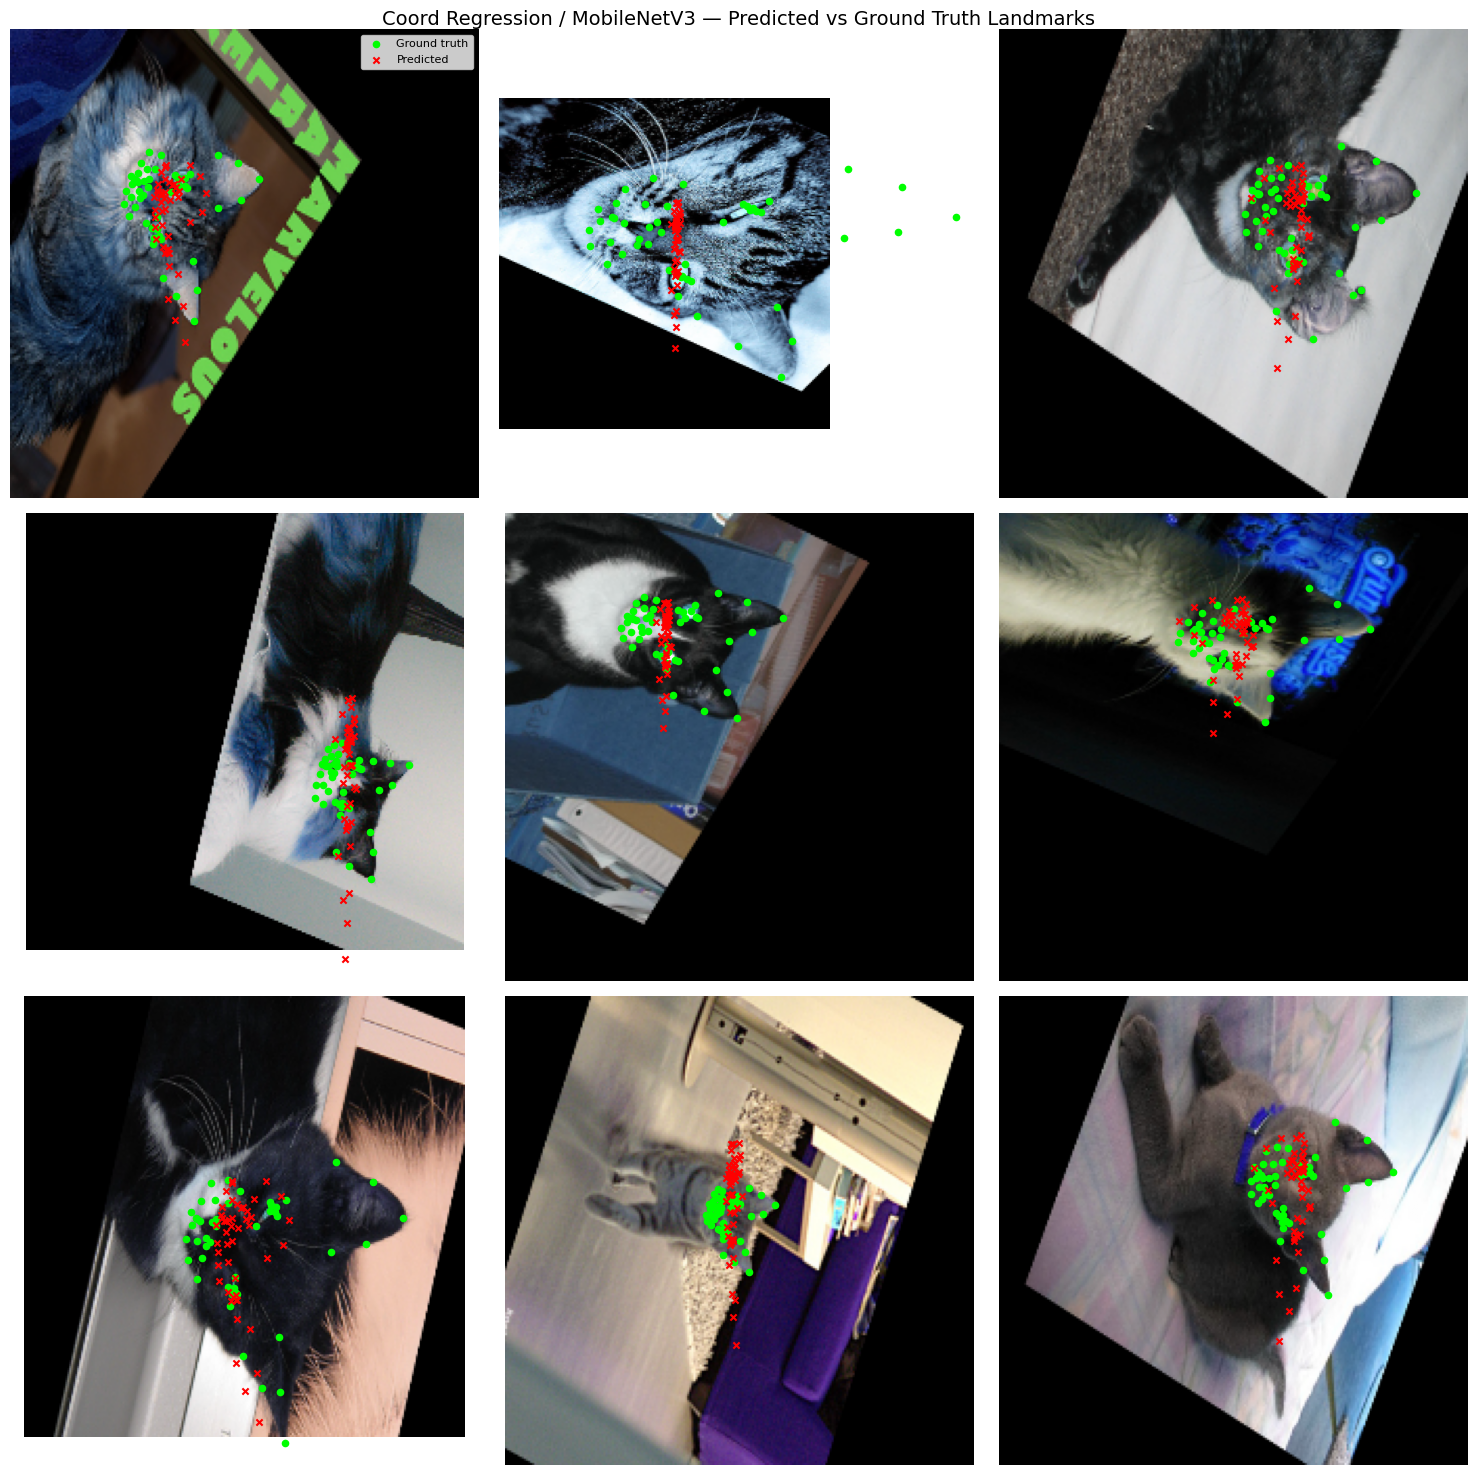

Saved to /content/drive/MyDrive/catflw_project/catflw_landmarks/visualizations/qualitative_results.png


In [ ]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

from catflw_dataset import (
    load_annotations,
    CatFLWDataset,
    train_val_test_split
)
from models import build_model

# Prepare the test dataset
records, image_dir = load_annotations(DATA_DIR)
_, _, test_records = train_val_test_split(records, seed=0)

test_dataset = CatFLWDataset(
    image_dir,
    test_records,
    target_type="coord",
    use_alignment=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# Load the trained MobileNetV3 model
device = "cuda" if torch.cuda.is_available() else "cpu"

model = build_model(
    "coord",
    "mobilenetv3_small_100",
    pretrained=False
).to(device)

checkpoint_path = Path(
    "runs/coord_mobilenet/coord_mobilenetv3_small_100.pt"
)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)
model.eval()

# Create output directory
visualization_dir = Path("visualizations")
visualization_dir.mkdir(parents=True, exist_ok=True)

# Visualize predictions on nine test images
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

with torch.no_grad():
    for i, batch in enumerate(test_loader):
        if i >= 9:
            break

        image = batch["image"].to(device)
        ground_truth = batch["landmarks_raw"][0].cpu().numpy()

        predictions = (
            model(image)[0]
            .cpu()
            .numpy()
            .reshape(-1, 2)
        )

        image_np = (
            image[0]
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

        axes[i].imshow(image_np)

        axes[i].scatter(
            ground_truth[:, 0],
            ground_truth[:, 1],
            c="lime",
            s=20,
            label="Ground truth"
        )

        axes[i].scatter(
            predictions[:, 0],
            predictions[:, 1],
            c="red",
            s=20,
            marker="x",
            label="Predicted"
        )

        axes[i].axis("off")

        if i == 0:
            axes[i].legend(loc="upper right", fontsize=8)

plt.suptitle(
    "MobileNetV3 Coordinate Regression: "
    "Predicted vs Ground Truth Landmarks",
    fontsize=14
)

plt.tight_layout()

save_path = visualization_dir / "qualitative_results.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Visualization saved to: {save_path}")

### 6.2 Model Comparison and Ablation Results

This section presents the quantitative results of the main model comparison and ablation experiments.

**Model comparison:** Six combinations of CNN architecture and regression approach are compared using test NRMSE. The published FGS benchmark of 16.76% is included as a reference.

**Ablation study:** The MobileNetV3 coordinate-regression baseline is compared against experiments that disable face alignment, enable edge filtering, or replace Wing loss with MSE loss.

Lower NRMSE values indicate more accurate facial landmark predictions. The charts use the results recorded from the completed experiments.

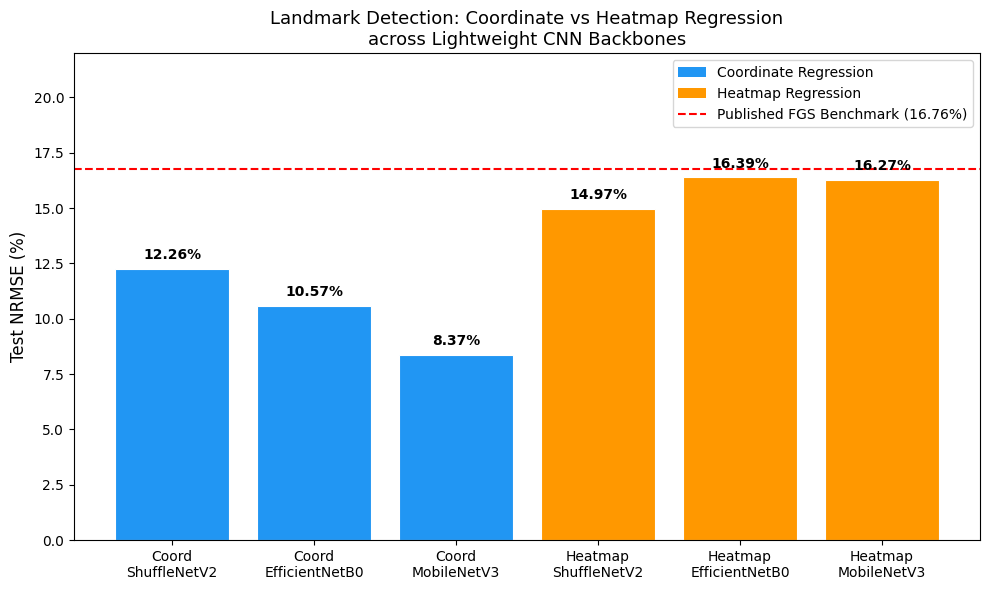

Saved comparison chart


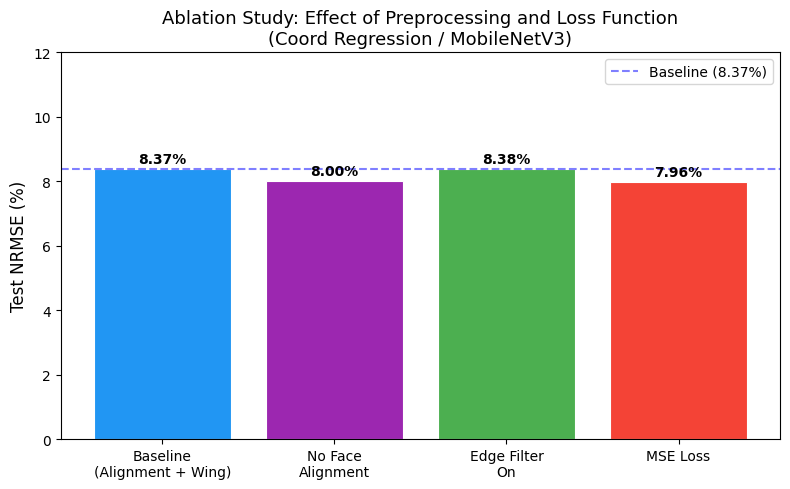

Saved ablation chart


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# Directory for saved figures
save_dir = Path("visualizations")
save_dir.mkdir(parents=True, exist_ok=True)

# 1. Main model comparison
results = {
    "Coord\nShuffleNetV2": 12.26,
    "Coord\nEfficientNetB0": 10.57,
    "Coord\nMobileNetV3": 8.37,
    "Heatmap\nShuffleNetV2": 14.97,
    "Heatmap\nEfficientNetB0": 16.39,
    "Heatmap\nMobileNetV3": 16.27,
}

labels = list(results.keys())
values = list(results.values())
colors = ["#2196F3"] * 3 + ["#FF9800"] * 3

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(labels, values, color=colors)

ax.axhline(
    16.76,
    color="red",
    linestyle="--",
    label="Published FGS benchmark (16.76%)"
)

ax.set_ylabel("Test NRMSE (%)")
ax.set_title(
    "Landmark Detection: Coordinate vs Heatmap Regression\n"
    "Across Lightweight CNN Backbones"
)
ax.set_ylim(0, 22)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.legend(handles=[
    Patch(facecolor="#2196F3", label="Coordinate Regression"),
    Patch(facecolor="#FF9800", label="Heatmap Regression"),
    plt.Line2D(
        [0], [0],
        color="red",
        linestyle="--",
        label="Published FGS Benchmark (16.76%)"
    )
])

plt.tight_layout()
plt.savefig(save_dir / "comparison_chart.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Ablation study
ablation_results = {
    "Baseline\n(Alignment + Wing)": 8.37,
    "No Face\nAlignment": 8.00,
    "Edge Filter\nOn": 8.38,
    "MSE Loss": 7.96,
}

labels = list(ablation_results.keys())
values = list(ablation_results.values())
colors = ["#2196F3", "#9C27B0", "#4CAF50", "#F44336"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, values, color=colors)

ax.axhline(
    8.37,
    color="blue",
    linestyle="--",
    alpha=0.5,
    label="Baseline (8.37%)"
)

ax.set_ylabel("Test NRMSE (%)")
ax.set_title(
    "Ablation Study: Preprocessing and Loss Function\n"
    "(Coordinate Regression / MobileNetV3)"
)
ax.set_ylim(0, 12)
ax.legend()

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(save_dir / "ablation_chart.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Charts saved to: {save_dir.resolve()}")

## 7. Repeated Training Experiments

To investigate the stability and reproducibility of the best-performing model, MobileNetV3 coordinate regression is trained multiple times using different random seeds.

Each experiment uses the same architecture, dataset, training configuration, and loss function. Only the random seed changes.

The resulting test NRMSE values are compared to evaluate how sensitive the model's performance is to randomness in training.

### 7.1 MobileNetV3 — Random Seed 1

The first repeated experiment trains MobileNetV3 coordinate regression using random seed 1. Its results are saved separately for comparison with subsequent runs.

In [ ]:
# Repeated experiment: MobileNetV3, seed 1
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/repeated_runs/seed_1" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --seed 1

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=88.9425 val_nrmse=17.28%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.6627 val_nrmse=12.48%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=31.5649 val_nrmse=12.67%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.5547 val_nrmse=12.85%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.4243 val_nrmse=12.50%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=30.2016 val_nrmse=12.71%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=29.8892 val_nrmse=13.18%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=29.7532 val_nrmse=12.38%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=29.3577 val_nrmse=12.05%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=29.6674 val_nrmse=12.14%
[coord/mobilenetv3_s

### 7.2 MobileNetV3 — Random Seed 2

The second repeated experiment trains MobileNetV3 coordinate regression using random seed 2.

The architecture, loss function, and training hyperparameters remain identical to the previous experiment. Changing the random seed allows us to investigate how randomness affects the model's landmark prediction accuracy.

The results are saved in a separate directory to allow comparison with the other training runs.

In [ ]:
# Repeated experiment: MobileNetV3, seed 2
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/repeated_runs/seed_2" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --seed 2

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=87.7409 val_nrmse=16.07%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.0239 val_nrmse=13.10%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=30.8432 val_nrmse=12.66%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.4295 val_nrmse=13.08%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=29.9698 val_nrmse=12.41%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.8081 val_nrmse=11.97%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=29.6379 val_nrmse=12.32%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=29.2559 val_nrmse=12.05%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=29.1404 val_nrmse=12.41%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=29.2741 val_nrmse=12.36%
[coord/mobilenetv3_s

### 7.3 MobileNetV3 — Random Seed 3

The third repeated experiment trains MobileNetV3 coordinate regression using random seed 3.

The model architecture, loss function, and training hyperparameters remain consistent with the previous repeated experiments.

By changing only the random seed, we can examine whether the model produces similar landmark detection accuracy across independent training runs.

The results are saved separately for subsequent statistical analysis.

In [ ]:
# Repeated experiment: MobileNetV3, seed 3
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/repeated_runs/seed_3" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --seed 3

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=87.4984 val_nrmse=15.26%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.2058 val_nrmse=12.54%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=30.8898 val_nrmse=12.41%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.4077 val_nrmse=12.52%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.0157 val_nrmse=12.30%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.8316 val_nrmse=12.22%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=29.2547 val_nrmse=12.10%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=29.3644 val_nrmse=12.17%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=29.1962 val_nrmse=12.46%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=29.0490 val_nrmse=12.25%
[coord/mobilenetv3_s

### 7.4 MobileNetV3 — Random Seed 110

The fourth repeated experiment trains MobileNetV3 coordinate regression using random seed 110.

The model architecture, loss function, and training hyperparameters remain consistent with the previous repeated experiments.

This additional run provides another measurement of model performance, helping assess the variability of landmark detection accuracy across different random seeds.

The results are saved in a separate directory for subsequent statistical analysis.

In [ ]:
# Repeated experiment: MobileNetV3, seed 110
!python train.py \
    --approach coord \
    --backbone mobilenetv3_small_100 \
    --data_dir "{DATA_DIR}" \
    --out_dir "runs/repeated_runs/seed_110" \
    --epochs 30 \
    --batch_size 16 \
    --lr 1e-4 \
    --seed 110

Using device: cuda
load_annotations: skipping unreadable image 00000057_001.png
load_annotations: skipped 1 label files (missing image or unexpected landmark count)
load_annotations: loaded 2078 valid records
[coord/mobilenetv3_small_100] epoch 1/30 train_loss=86.5304 val_nrmse=15.53%
[coord/mobilenetv3_small_100] epoch 2/30 train_loss=32.1269 val_nrmse=12.12%
[coord/mobilenetv3_small_100] epoch 3/30 train_loss=31.0418 val_nrmse=12.53%
[coord/mobilenetv3_small_100] epoch 4/30 train_loss=30.3955 val_nrmse=13.05%
[coord/mobilenetv3_small_100] epoch 5/30 train_loss=30.2357 val_nrmse=12.64%
[coord/mobilenetv3_small_100] epoch 6/30 train_loss=29.9259 val_nrmse=12.45%
[coord/mobilenetv3_small_100] epoch 7/30 train_loss=29.7825 val_nrmse=12.39%
[coord/mobilenetv3_small_100] epoch 8/30 train_loss=29.4748 val_nrmse=12.81%
[coord/mobilenetv3_small_100] epoch 9/30 train_loss=29.7069 val_nrmse=12.40%
[coord/mobilenetv3_small_100] epoch 10/30 train_loss=29.1864 val_nrmse=12.35%
[coord/mobilenetv3_s

### 7.5 Statistical Summary of Repeated Runs

To assess the consistency of MobileNetV3 coordinate regression, the test NRMSE values from five training runs are summarized.

The mean provides an estimate of average model performance, while the standard deviation measures the variability between runs. The minimum and maximum values show the range of observed performance.

Lower NRMSE values indicate more accurate facial landmark predictions.

The values below are taken from the recorded experiment results rather than recalculated from model checkpoints.

In [ ]:
import numpy as np

# Recorded test NRMSE (%) from five MobileNetV3 runs
results = [8.37, 8.67, 7.76, 8.74, 8.64]

mean_nrmse = np.mean(results)
std_nrmse = np.std(results)
min_nrmse = np.min(results)
max_nrmse = np.max(results)

print("MobileNetV3 Coordinate Regression — Repeated Runs")
print(f"Number of runs: {len(results)}")
print(f"Mean NRMSE:     {mean_nrmse:.2f}%")
print(f"Std deviation:  {std_nrmse:.2f}%")
print(f"Minimum NRMSE:  {min_nrmse:.2f}%")
print(f"Maximum NRMSE:  {max_nrmse:.2f}%")

Mean: 8.44%
Std:  0.36%
Min:  7.76%
Max:  8.74%


### 7.6 Training Convergence Analysis

This section examines how validation NRMSE changes over 30 training epochs for the six model configurations.

Separate plots are presented for coordinate regression and heatmap regression, allowing the convergence behaviour of ShuffleNetV2, EfficientNetB0, and MobileNetV3 to be compared.

The FGS benchmark of 16.76% is included as a reference.

The curves use validation NRMSE values recorded during the original training experiments. The percentages shown in the legends represent the corresponding test NRMSE results.

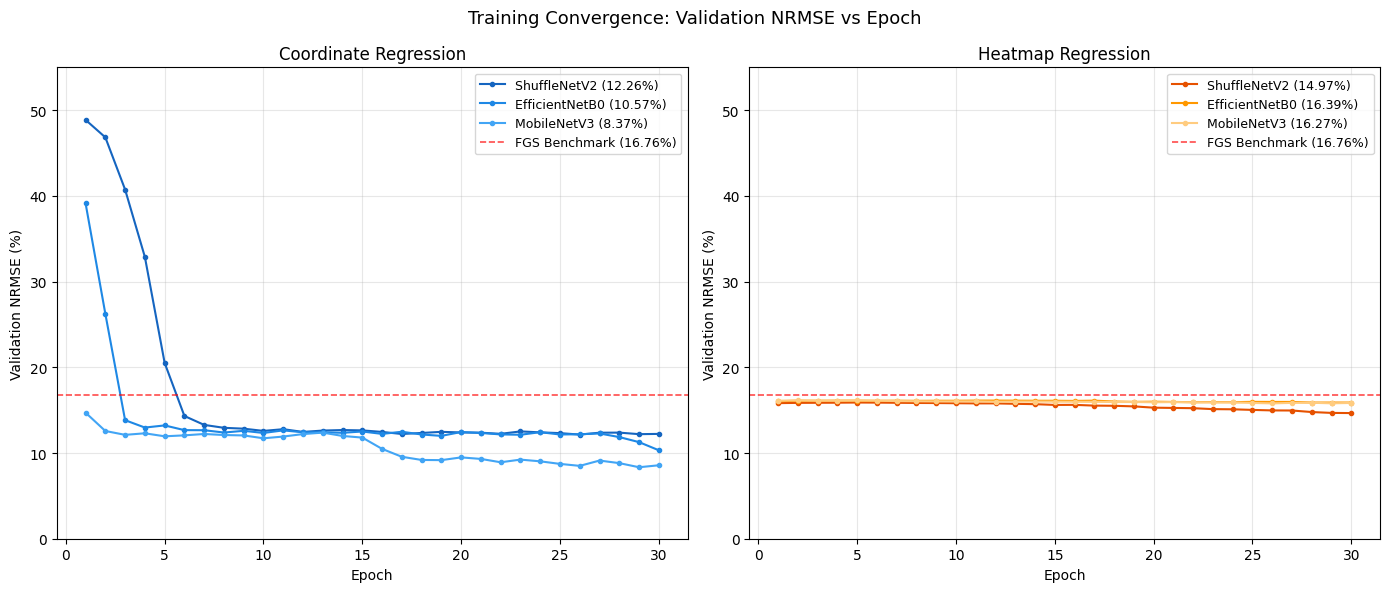

Saved convergence_curves.png


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

# Save visualizations locally
save_dir = Path("visualizations")
save_dir.mkdir(parents=True, exist_ok=True)

epochs = list(range(1, 31))

# Coordinate regression val NRMSE per epoch
coord_shufflenet  = [48.87,46.83,40.74,32.88,20.52,14.32,13.28,12.94,12.84,12.58,12.78,12.46,12.62,12.68,12.64,12.46,12.22,12.34,12.47,12.40,12.37,12.24,12.52,12.41,12.32,12.15,12.37,12.38,12.20,12.23]
coord_efficientnet = [39.14,26.25,13.83,12.97,13.22,12.67,12.66,12.39,12.59,12.34,12.64,12.42,12.42,12.36,12.51,12.23,12.48,12.16,12.00,12.45,12.34,12.17,12.13,12.43,12.16,12.19,12.28,11.86,11.27,10.32]
coord_mobilenet    = [14.71,12.57,12.12,12.30,11.95,12.06,12.22,12.10,12.05,11.72,11.92,12.21,12.38,11.99,11.80,10.48,9.56,9.19,9.17,9.49,9.31,8.92,9.23,9.03,8.73,8.50,9.12,8.82,8.34,8.57]

# Heatmap regression val NRMSE per epoch
heatmap_shufflenet   = [15.82,15.85,15.86,15.87,15.89,15.88,15.86,15.84,15.83,15.81,15.79,15.79,15.74,15.70,15.61,15.62,15.53,15.51,15.44,15.29,15.26,15.23,15.12,15.10,15.03,14.97,14.96,14.78,14.68,14.66]
heatmap_efficientnet = [16.04,16.10,16.10,16.11,16.11,16.09,16.11,16.09,16.10,16.10,16.12,16.12,16.11,16.10,16.10,16.08,16.11,16.01,15.97,15.99,15.96,15.93,15.94,15.93,15.97,15.96,15.96,15.89,15.89,15.89]
heatmap_mobilenet    = [16.10,16.15,16.11,16.11,16.13,16.11,16.06,16.04,16.02,16.02,16.02,15.98,16.00,16.00,15.99,15.98,15.97,15.95,15.95,15.92,15.94,15.91,15.90,15.90,15.84,15.79,15.85,15.86,15.80,15.84]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Coord regression
ax1.plot(epochs, coord_shufflenet,   marker="o", markersize=3, label="ShuffleNetV2 (12.26%)",   color="#1565C0")
ax1.plot(epochs, coord_efficientnet, marker="o", markersize=3, label="EfficientNetB0 (10.57%)", color="#1E88E5")
ax1.plot(epochs, coord_mobilenet,    marker="o", markersize=3, label="MobileNetV3 (8.37%)",     color="#42A5F5")
ax1.axhline(y=16.76, color="red", linestyle="--", linewidth=1.2, alpha=0.7, label="FGS Benchmark (16.76%)")
ax1.set_title("Coordinate Regression", fontsize=12)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Validation NRMSE (%)")
ax1.legend(fontsize=9)
ax1.set_ylim(0, 55)
ax1.grid(True, alpha=0.3)

# Heatmap regression
ax2.plot(epochs, heatmap_shufflenet,   marker="o", markersize=3, label="ShuffleNetV2 (14.97%)",   color="#E65100")
ax2.plot(epochs, heatmap_efficientnet, marker="o", markersize=3, label="EfficientNetB0 (16.39%)", color="#FF9800")
ax2.plot(epochs, heatmap_mobilenet,    marker="o", markersize=3, label="MobileNetV3 (16.27%)",    color="#FFCC80")
ax2.axhline(y=16.76, color="red", linestyle="--", linewidth=1.2, alpha=0.7, label="FGS Benchmark (16.76%)")
ax2.set_title("Heatmap Regression", fontsize=12)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Validation NRMSE (%)")
ax2.legend(fontsize=9)
ax2.set_ylim(0, 55)
ax2.grid(True, alpha=0.3)

plt.suptitle("Training Convergence: Validation NRMSE vs Epoch", fontsize=13)
plt.tight_layout()
plt.savefig(
    save_dir / "convergence_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
print("Saved convergence_curves.png")

### 7.7 Statistical Significance Testing

A one-sample t-test is performed to compare the mean test NRMSE of MobileNetV3 coordinate regression against the published FGS benchmark of 16.76%.

The analysis uses five recorded NRMSE results from independent training runs.

**Hypotheses:**

- **Null hypothesis (H₀):** The mean NRMSE equals the benchmark value of 16.76%.
- **Alternative hypothesis (H₁):** The mean NRMSE differs from 16.76%.

A significance level of 0.05 is used. A p-value below this threshold indicates statistically significant evidence that the mean differs from the benchmark.

Since lower NRMSE indicates better performance, the direction of the observed difference is also considered when interpreting the results.

In [ ]:
from scipy import stats
import numpy as np

# Recorded MobileNetV3 coordinate-regression test NRMSE (%)
results = np.array([8.37, 8.67, 7.76, 8.74, 8.64])

# Published FGS benchmark NRMSE (%)
benchmark = 16.76
alpha = 0.05

# One-sample, two-sided t-test
t_stat, p_value = stats.ttest_1samp(results, benchmark)

# Summary statistics
mean_nrmse = np.mean(results)
std_nrmse = np.std(results, ddof=1)

print("MobileNetV3 vs FGS Benchmark")
print(f"Number of runs:       {len(results)}")
print(f"Mean NRMSE:           {mean_nrmse:.2f}%")
print(f"Sample std deviation: {std_nrmse:.2f}%")
print(f"FGS benchmark:        {benchmark:.2f}%")
print(f"t-statistic:          {t_stat:.4f}")
print(f"p-value:              {p_value:.6f}")
print(f"Significant (p < 0.05): {p_value < alpha}")

Mean: 8.44%
Std: 0.40%
t-statistic: -46.1690
p-value: 0.000001
Significant at p<0.05: True
